creation de la target

Objectif : Créer la variable cible du projet à partir d'un signal ajusté à la volatilité.

Méthodologie retenue : Volatility Adjusted Signal 

Logique :

BUY :
rendement futur > volatilité récente

SELL :
rendement futur < - volatilité récente

HOLD :
cas intermédiaire

Cette méthode a été retenue parceque l'ajustement dynamique permet d'adapter automatiquement le signal aux conditions de marché. Le marché de la crypto est trés volatile. Un seuil fixe n'a pas le même sens dans un marché calme ou dans un marché volatil.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt  

In [2]:
FEATURE_DATA_PATH = Path("../data/final")
TARGET_DATA_PATH = Path("../data/final")

TARGET_DATA_PATH.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(FEATURE_DATA_PATH / "BTCUSD_features.csv")

df["date"] = pd.to_datetime(df["date"])

df.head()

,symbol,date,open,high,low,close,volume,change,changePercent,vwap,...,dist_sma,dist_ema,rsi,BB_middle,BB_upper,BB_lower,BB_width,BB_percent,trend_signal,return_acceleration
0,BTCUSD,2012-04-17,4.95914,5.02207,4.92500,4.97587,0,0.01673,0.33736,4.97052,...,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
1,BTCUSD,2012-04-18,4.97587,5.17820,4.96000,5.11780,0,0.14193,2.85237,5.05797,...,NaN,0.025737,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
2,BTCUSD,2012-04-19,5.11760,5.19000,5.10000,5.13766,0,0.02006,0.39198,5.13632,...,NaN,0.026812,NaN,NaN,NaN,NaN,NaN,NaN,0,-0.024643
3,BTCUSD,2012-04-20,5.13755,5.48000,5.10103,5.35000,0,0.21245,4.13524,5.26714,...,NaN,0.062244,NaN,NaN,NaN,NaN,NaN,NaN,0,0.037450
4,BTCUSD,2012-04-21,5.39771,5.47900,5.11000,5.26008,0,-0.13763,-2.54979,5.31170,...,NaN,0.039994,NaN,NaN,NaN,NaN,NaN,NaN,0,-0.058138


In [3]:
# Rendement futur sur 5 jours

df["future_return_5"] = (df["close"].shift(-5) / df["close"]) - 1

In [5]:
#création de la target

conditions = [df["future_return_5"] > df["volatility_20"], df["future_return_5"] < -df["volatility_20"]]

choices = [1,-1]

df["target"] = np.select(conditions, choices, default=0)

#Visualisation des classes créées
print(df["target"].value_counts())

print()

print(
    round(df["target"].value_counts(normalize=True)*100, 2))

target
 0    2002
 1    1757
-1    1241
Name: count, dtype: int64

target
 0    40.04
 1    35.14
-1    24.82
Name: proportion, dtype: float64


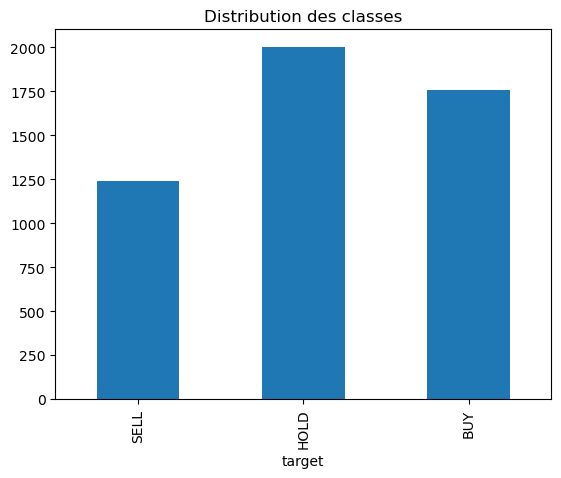

In [7]:
# visualisation de la distribution

df["target"].value_counts().sort_index().plot(kind="bar")

plt.xticks([0,1,2],["SELL","HOLD","BUY"])

plt.title("Distribution des classes")

plt.show()

In [8]:
# verication de la cohérence de la target

coherence = (df.groupby("target")["future_return_5"].mean())

print(coherence)

target
-1   -0.084154
 0    0.001128
 1    0.097758
Name: future_return_5, dtype: float64


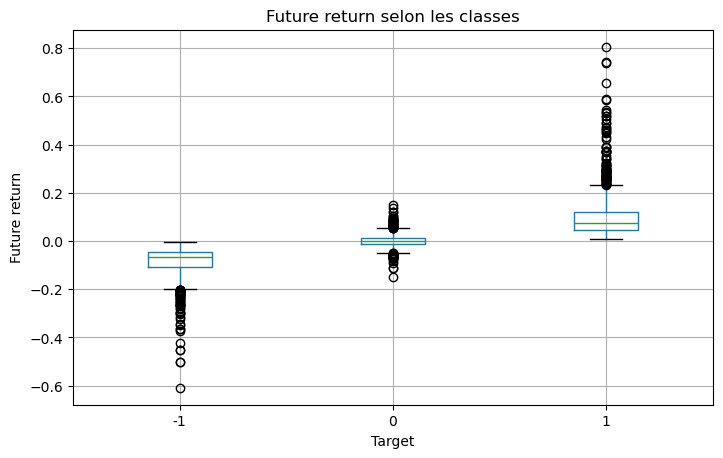

In [9]:
df.boxplot(column="future_return_5", by="target", figsize=(8,5))

plt.suptitle("")

plt.title("Future return selon les classes")

plt.xlabel("Target")

plt.ylabel("Future return")

plt.show()

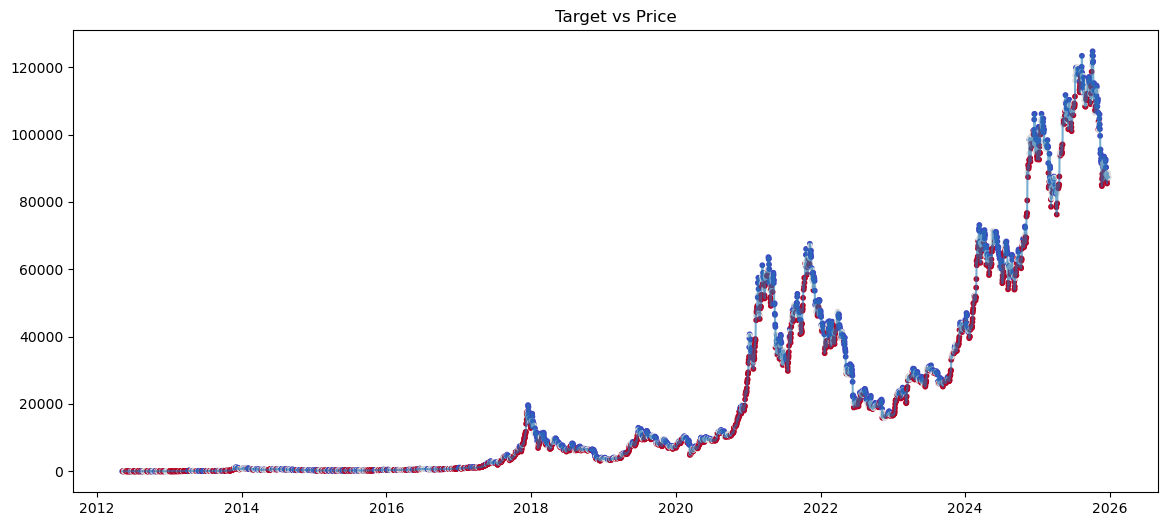

In [11]:
plt.figure(figsize=(14,6))
plt.plot(df["date"], df["close"], alpha=0.6)

plt.scatter(df["date"], df["close"], 
            c=df["target"], cmap="coolwarm", s=10)

plt.title("Target vs Price")
plt.show()

In [10]:
print("Avant :",len(df))

df = df.dropna()

print("Après :",len(df))

Avant : 5000
Après : 4975


In [12]:
df.to_csv(TARGET_DATA_PATH / "BTCUSD_model_base.csv",index=False)

print("Dataset final sauvegardé.")

Dataset final sauvegardé.
